## Requiremenmts

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime
import matplotlib.dates as mdates
import os
from scipy.spatial.distance import mahalanobis
from scipy.stats import chi2
from matplotlib.patches import Patch

## Get Data

In [2]:
# --- CONFIGURATION ---
start_date = "2019-06-20"
end_date = datetime.date.today().strftime("%Y-%m-%d")


Processing NIFTY_50 from NIFTY_50_EOD_Features.csv...
 -> Saved Analyzed Data: Market_Anomaly_Data_Updated\NIFTY_50_ANALYZED_ZSCORES.csv


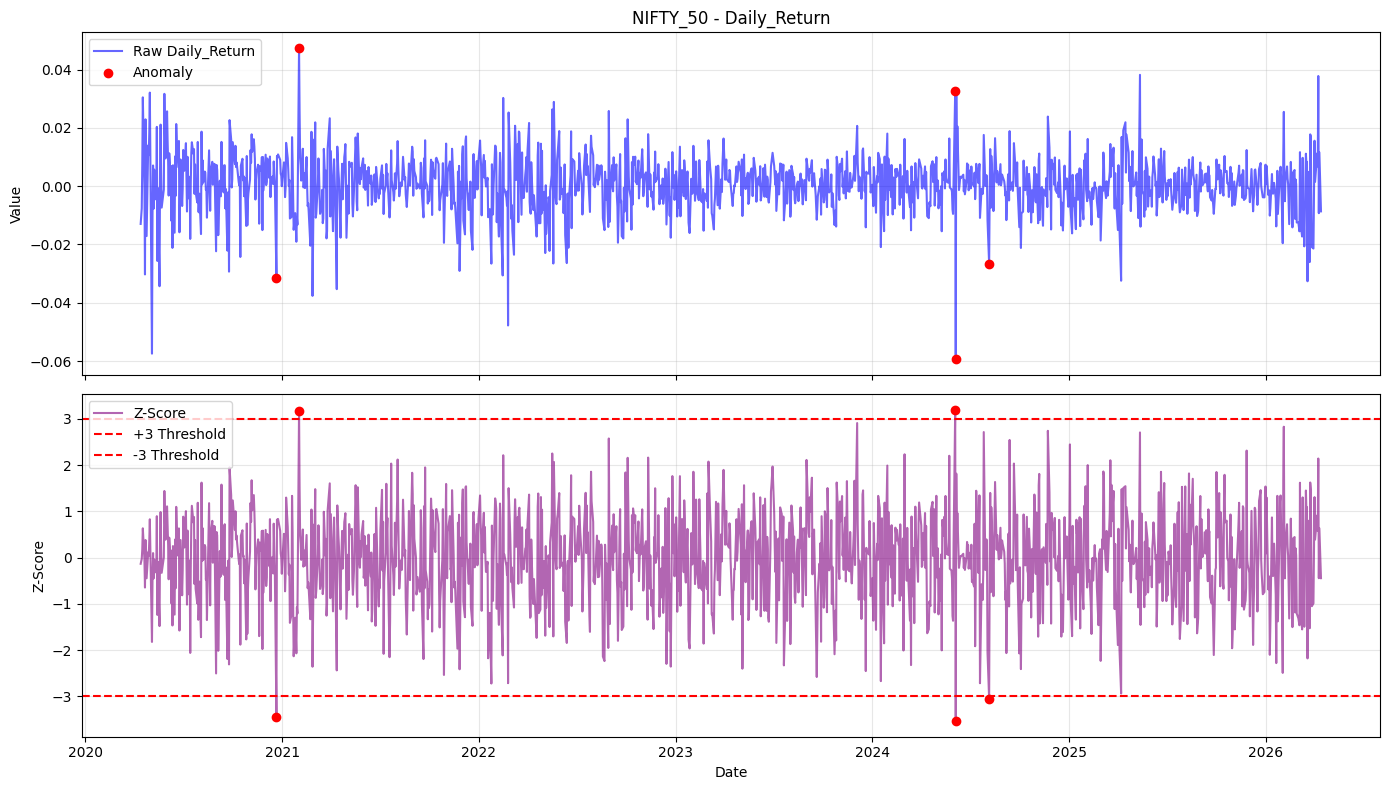

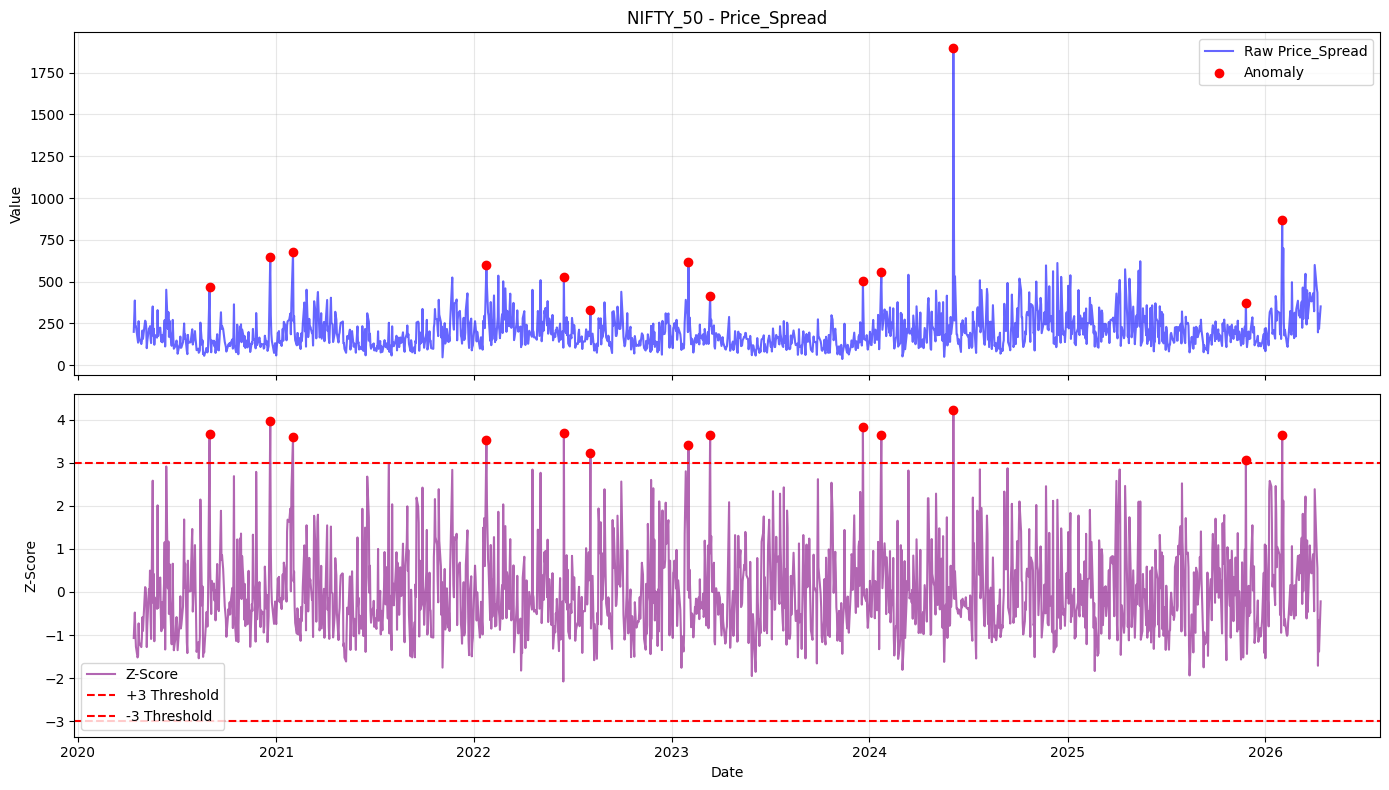

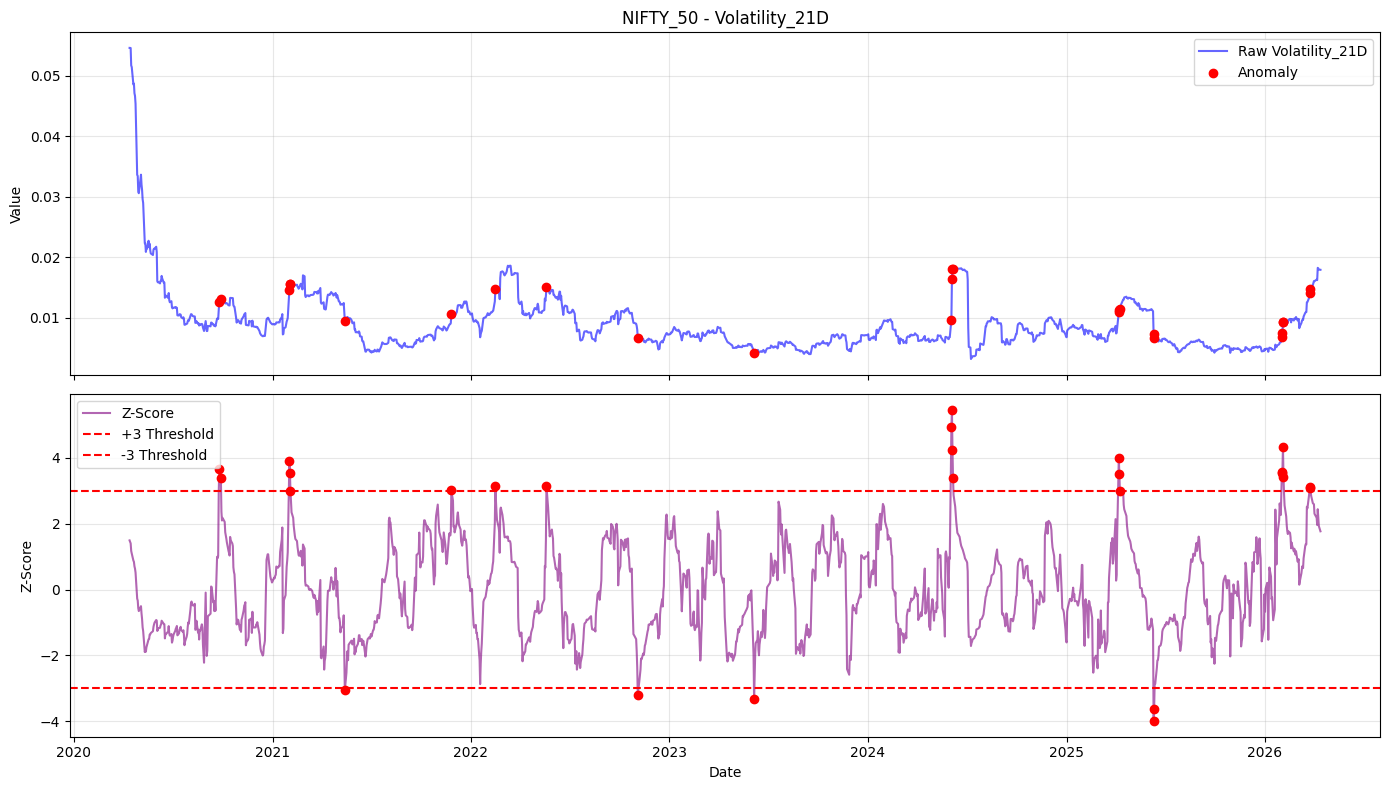


Processing NIFTY_MIDCAP_150 from NIFTY_MIDCAP_150_EOD_Features.csv...
 -> Saved Analyzed Data: Market_Anomaly_Data_Updated\NIFTY_MIDCAP_150_ANALYZED_ZSCORES.csv


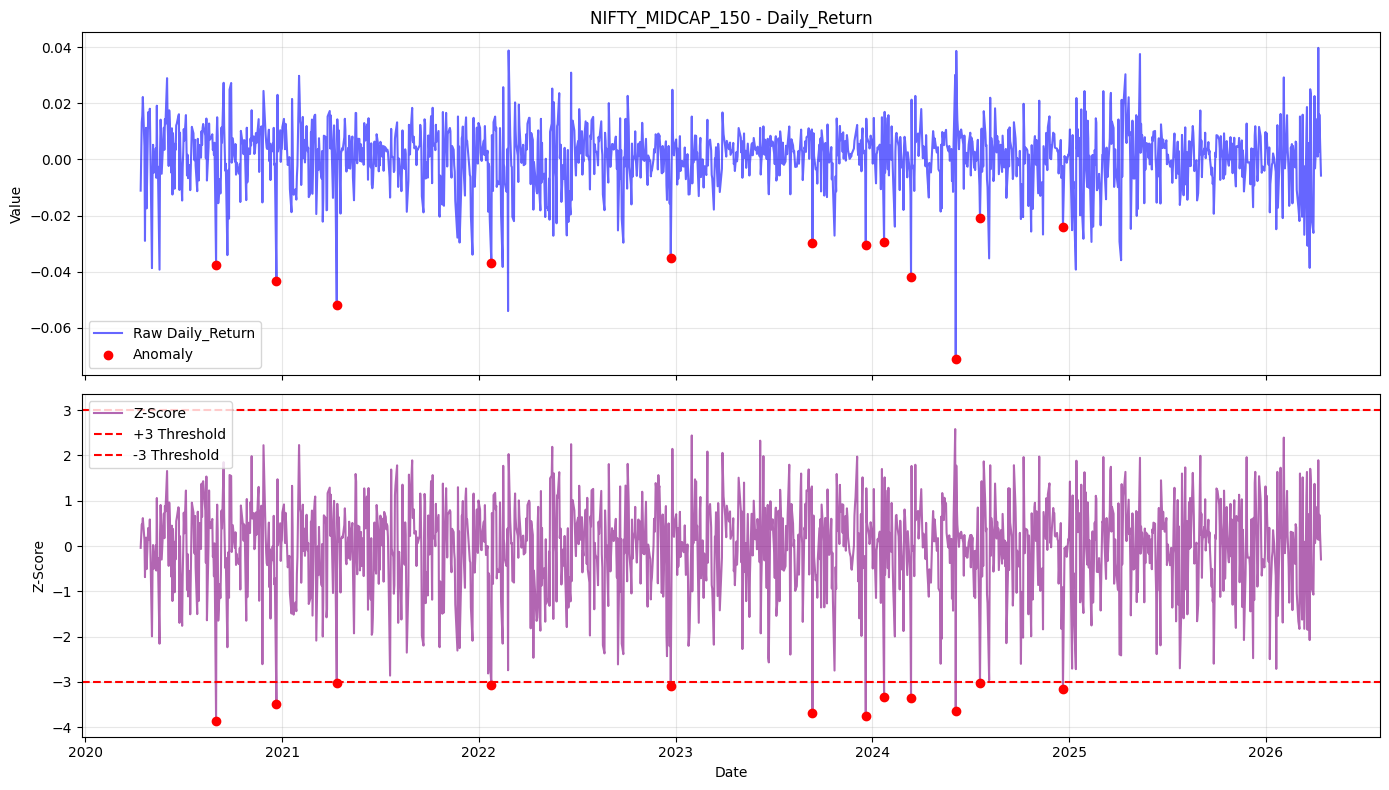

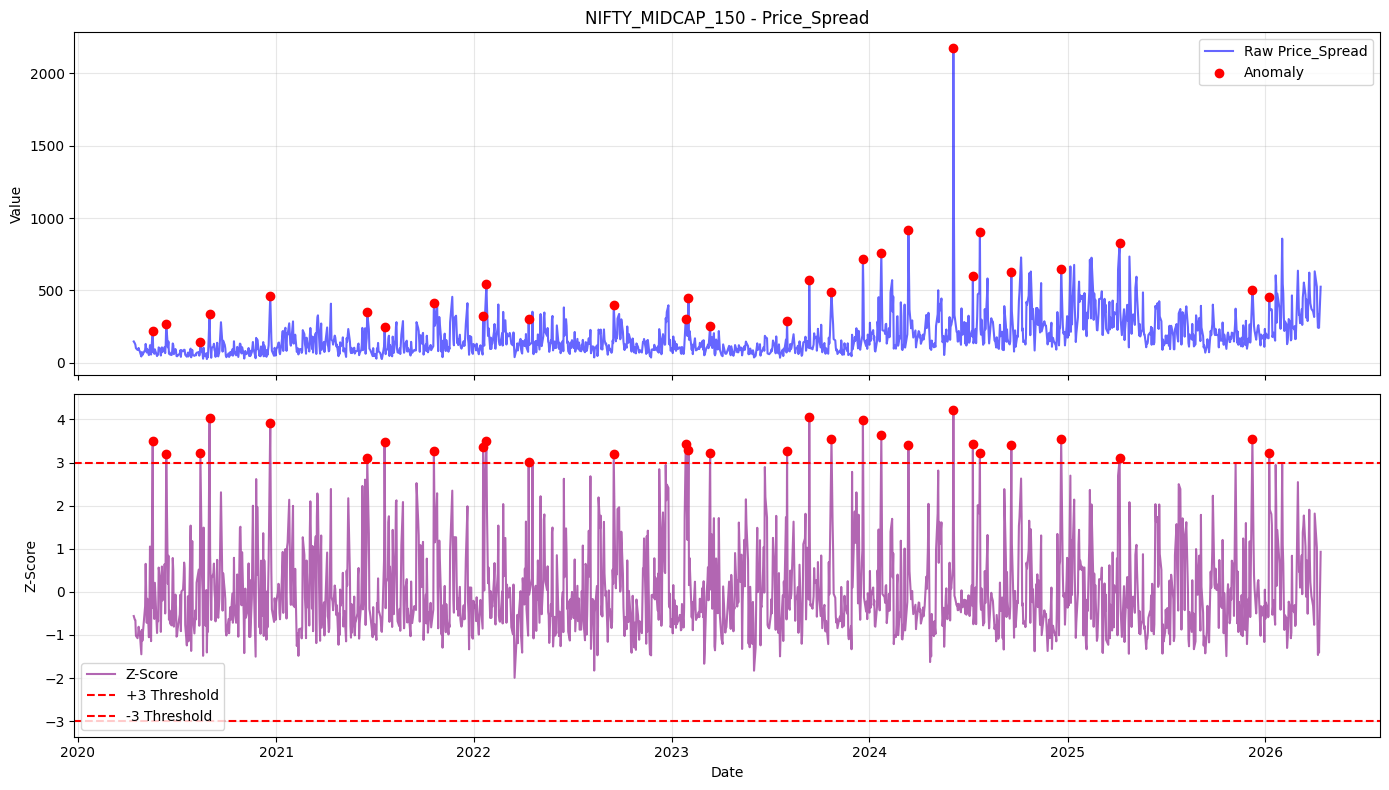

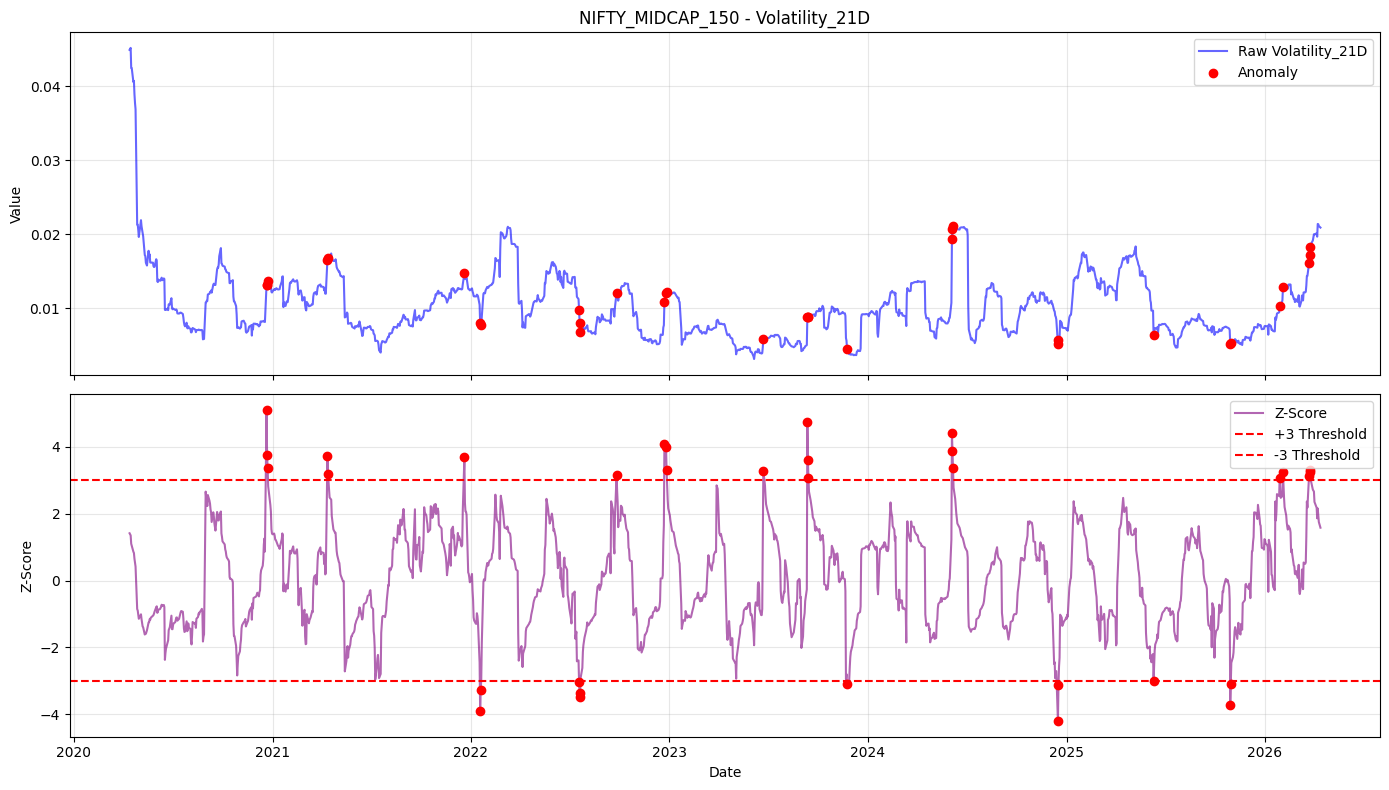


Processing NIFTY_SMALLCAP_250 from NIFTY_SMALLCAP_250_EOD_Features.csv...
 -> Saved Analyzed Data: Market_Anomaly_Data_Updated\NIFTY_SMALLCAP_250_ANALYZED_ZSCORES.csv


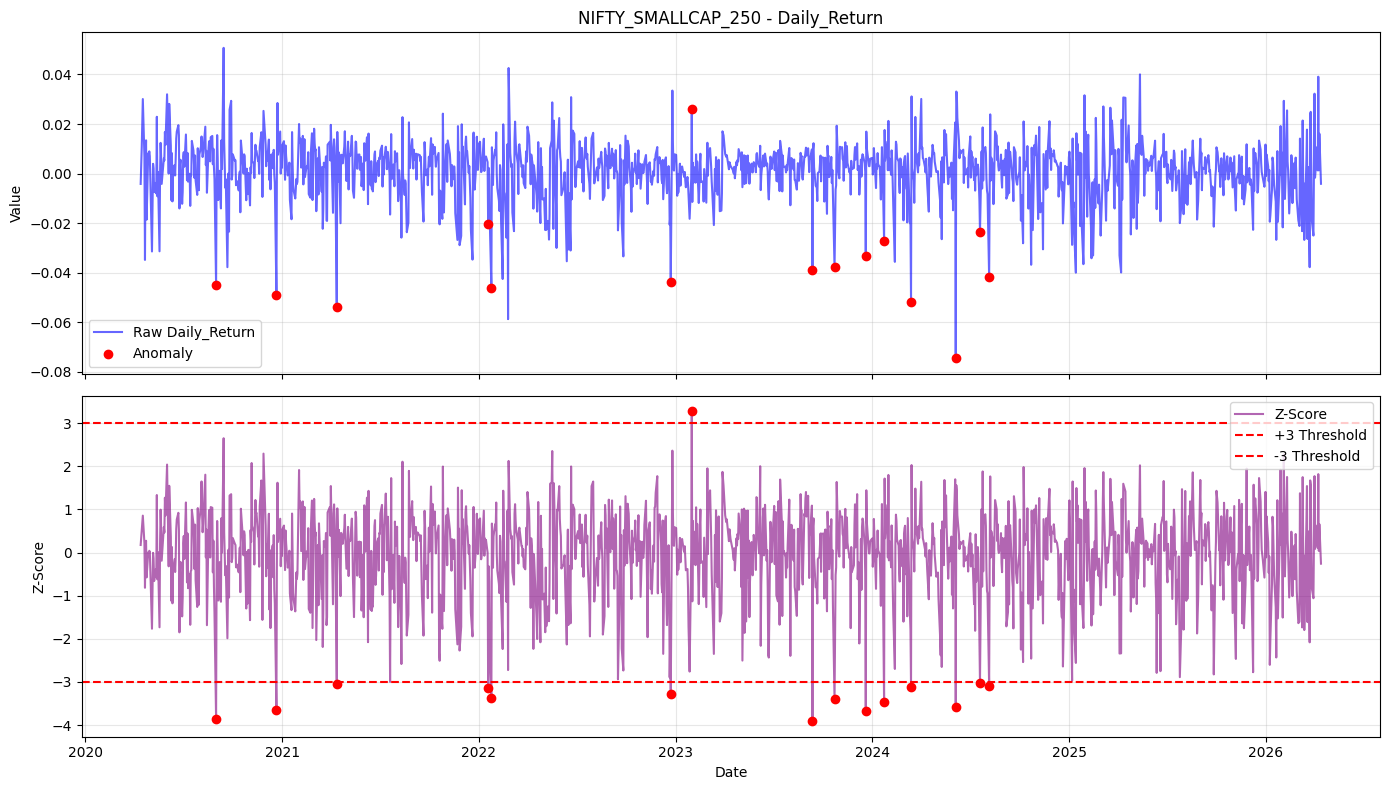

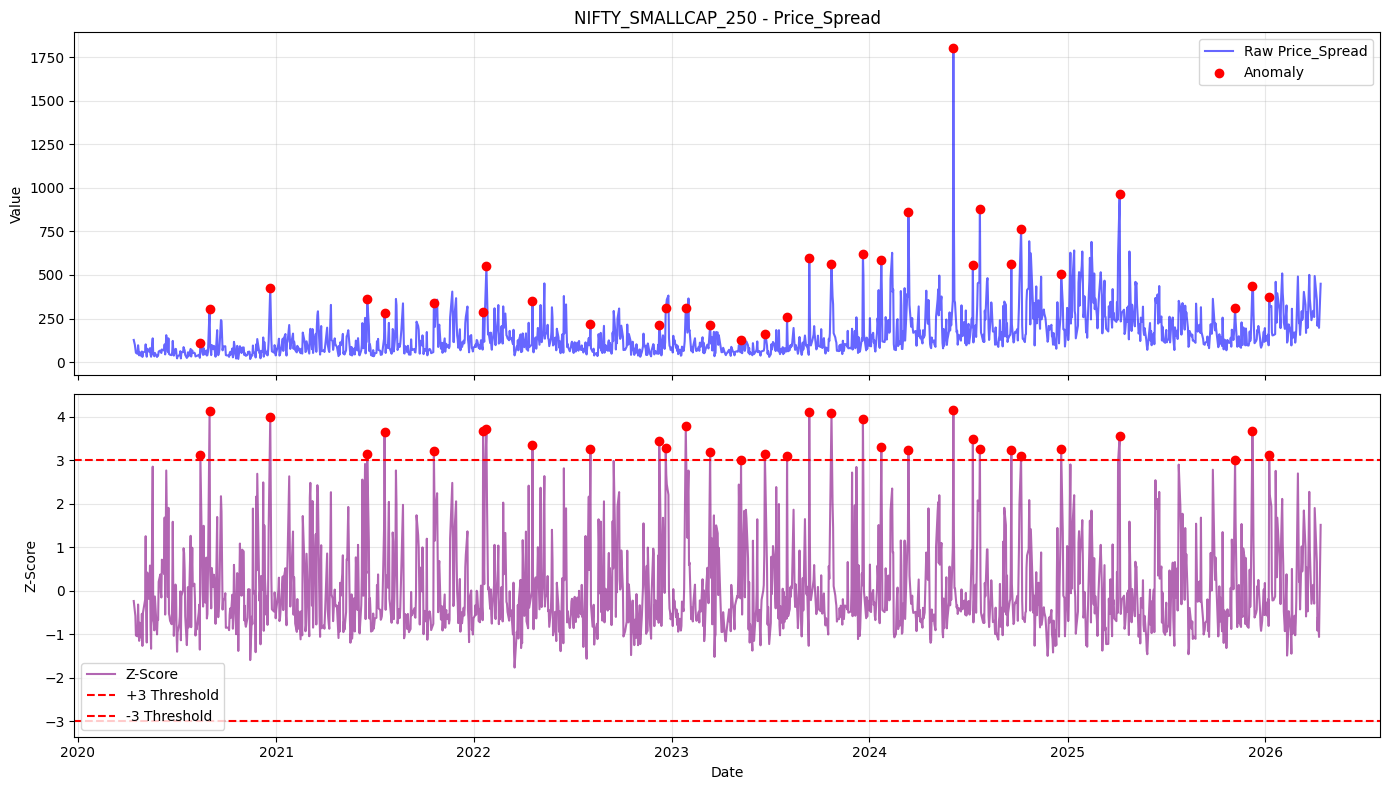

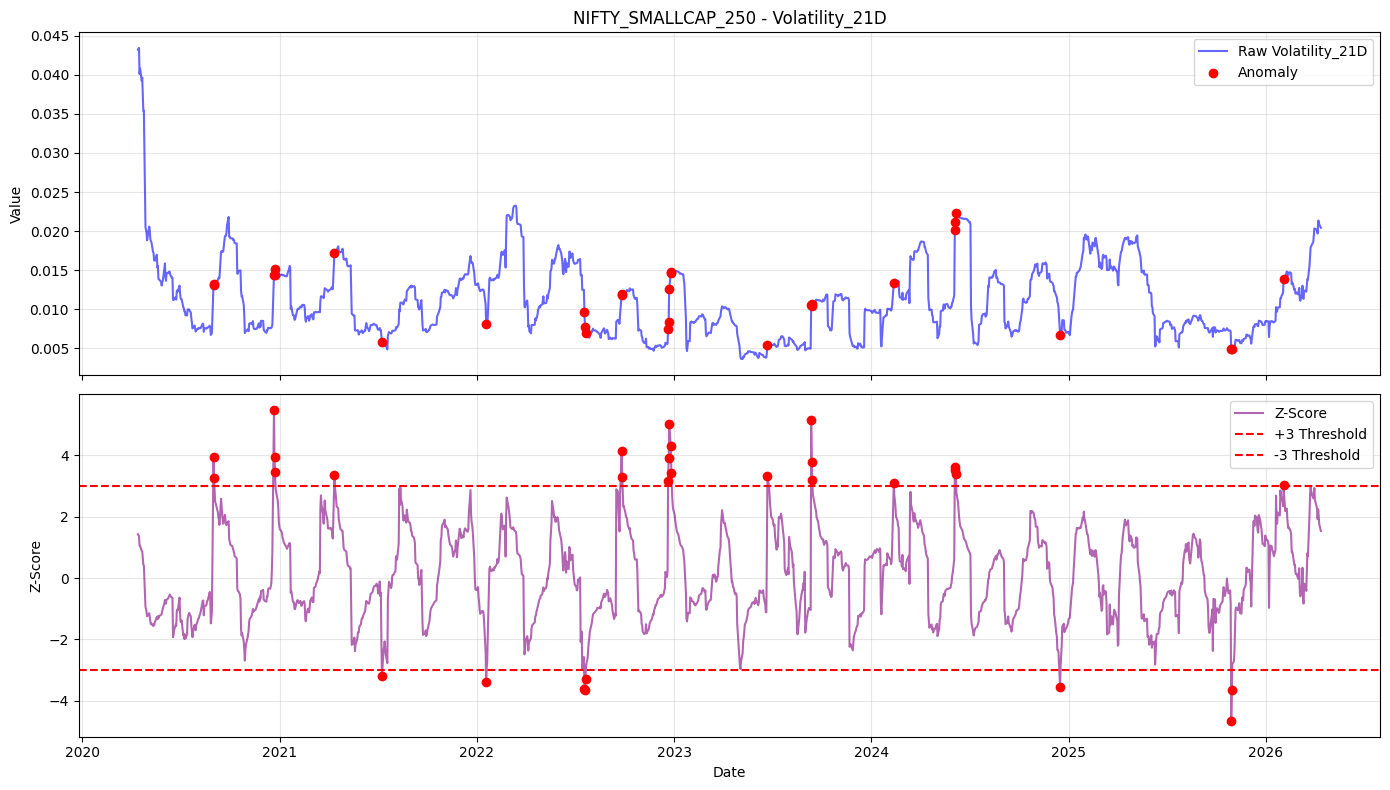


Pipeline Execution Complete!


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# --- CONFIGURATION ---
# Map names to your local CSV files
csv_files = {
    "NIFTY_50": "NIFTY_50_EOD_Features.csv",
    "NIFTY_MIDCAP_150": "NIFTY_MIDCAP_150_EOD_Features.csv",
    "NIFTY_SMALLCAP_250": "NIFTY_SMALLCAP_250_EOD_Features.csv"
}

# Create a directory to store the newly analyzed CSVs
output_dir = "Market_Anomaly_Data_Updated"
os.makedirs(output_dir, exist_ok=True)

# Helper function to plot anomalies
def plot_anomalies(df, feature_name, z_col_name, title):
    # Filter for anomalies (Z-score > 3 or < -3)
    anomalies = df[df[z_col_name].abs() > 3]
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    
    # Plot 1: Raw Feature Value
    ax1.plot(df.index, df[feature_name], label=f'Raw {feature_name}', color='blue', alpha=0.6)
    ax1.scatter(anomalies.index, anomalies[feature_name], color='red', label='Anomaly', zorder=5)
    ax1.set_title(f"{title} - {feature_name}")
    ax1.set_ylabel('Value')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Plot 2: Z-Score
    ax2.plot(df.index, df[z_col_name], label='Z-Score', color='purple', alpha=0.6)
    ax2.axhline(3, color='red', linestyle='--', label='+3 Threshold')
    ax2.axhline(-3, color='red', linestyle='--', label='-3 Threshold')
    ax2.scatter(anomalies.index, anomalies[z_col_name], color='red', zorder=5)
    ax2.set_ylabel('Z-Score')
    ax2.set_xlabel('Date')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# --- MAIN PIPELINE ---

for name, filename in csv_files.items():
    print(f"\nProcessing {name} from {filename}...")
    
    # ==========================================
    # PHASE 1: Load Local Data
    # ==========================================
    if not os.path.exists(filename):
        print(f"File {filename} not found. Ensure it is in the same directory. Skipping.")
        continue

    # Load the CSV. We set the Date column as the index for time-series operations.
    df = pd.read_csv(filename, index_col='Date', parse_dates=True)
    
    if df.empty:
        print(f"No data found in {filename}. Skipping.")
        continue
        
    # ==========================================
    # PHASE 2: Calculate Features & Z-Scores
    # ==========================================
    
    # 1. Daily Return (Percentage Change)
    df['Daily_Return'] = df['Close'].pct_change()
    
    # 2. Price Spread
    df['Price_Spread'] = df['High'] - df['Low']
    
    # 4. Realized Volatility (21-Day rolling standard deviation of returns)
    df['Volatility_21D'] = df['Daily_Return'].rolling(window=21).std()
    
    # --- Z-SCORE CALCULATIONS ---
    
    # Z-Score: Daily Return (21-Day Baseline)
    roll_mean_ret = df['Daily_Return'].rolling(window=21).mean()
    roll_std_ret = df['Daily_Return'].rolling(window=21).std()
    df['Z_Return'] = (df['Daily_Return'] - roll_mean_ret) / roll_std_ret
    
    # Z-Score: Trading Volume (21-Day Baseline)
    #roll_mean_vol = df['Volume'].rolling(window=21).mean()
    #roll_std_vol = df['Volume'].rolling(window=21).std()
    #df['Z_Volume'] = (df['Volume'] - roll_mean_vol) / roll_std_vol
    
    # Z-Score: Price Spread (21-Day Baseline)
    roll_mean_spr = df['Price_Spread'].rolling(window=21).mean()
    roll_std_spr = df['Price_Spread'].rolling(window=21).std()
    df['Z_Spread'] = (df['Price_Spread'] - roll_mean_spr) / roll_std_spr
    
    # Z-Score: Volatility (36-Day Baseline for the 21-Day Feature)
    roll_mean_volat = df['Volatility_21D'].rolling(window=36).mean()
    roll_std_volat = df['Volatility_21D'].rolling(window=36).std()
    df['Z_Volatility'] = (df['Volatility_21D'] - roll_mean_volat) / roll_std_volat
    
    # Save the analyzed data containing the new Z-Scores
    analyzed_filename = os.path.join(output_dir, f"{name}_ANALYZED_ZSCORES.csv")
    df.to_csv(analyzed_filename)
    print(f" -> Saved Analyzed Data: {analyzed_filename}")
    
    # ==========================================
    # PHASE 3: Visualizations
    # ==========================================
    # Bulletproof date-filtering method to replace .last('3Y')
    cutoff_date = df.index.max() - pd.DateOffset(years=6)
    df_recent = df[df.index >= cutoff_date]
    
    # Uncomment the feature you want to visualize right now:
    plot_anomalies(df_recent, 'Daily_Return', 'Z_Return', name)
    #plot_anomalies(df_recent, 'Volume', 'Z_Volume', name)
    plot_anomalies(df_recent, 'Price_Spread', 'Z_Spread', name)
    plot_anomalies(df_recent, 'Volatility_21D', 'Z_Volatility', name)

print("\nPipeline Execution Complete!")

Anomaly threshold (Mahalanobis distance): 4.0331

NIFTY_50: 2464 rows  |  115 anomalies detected
NIFTY_MIDCAP_150: 1667 rows  |  66 anomalies detected
NIFTY_SMALLCAP_250: 1667 rows  |  77 anomalies detected

Plot saved → D:\FIMIS\FIMIS_Paper\Z Only\Market_Anomaly_Data_Updated\nifty_anomaly_detection.png


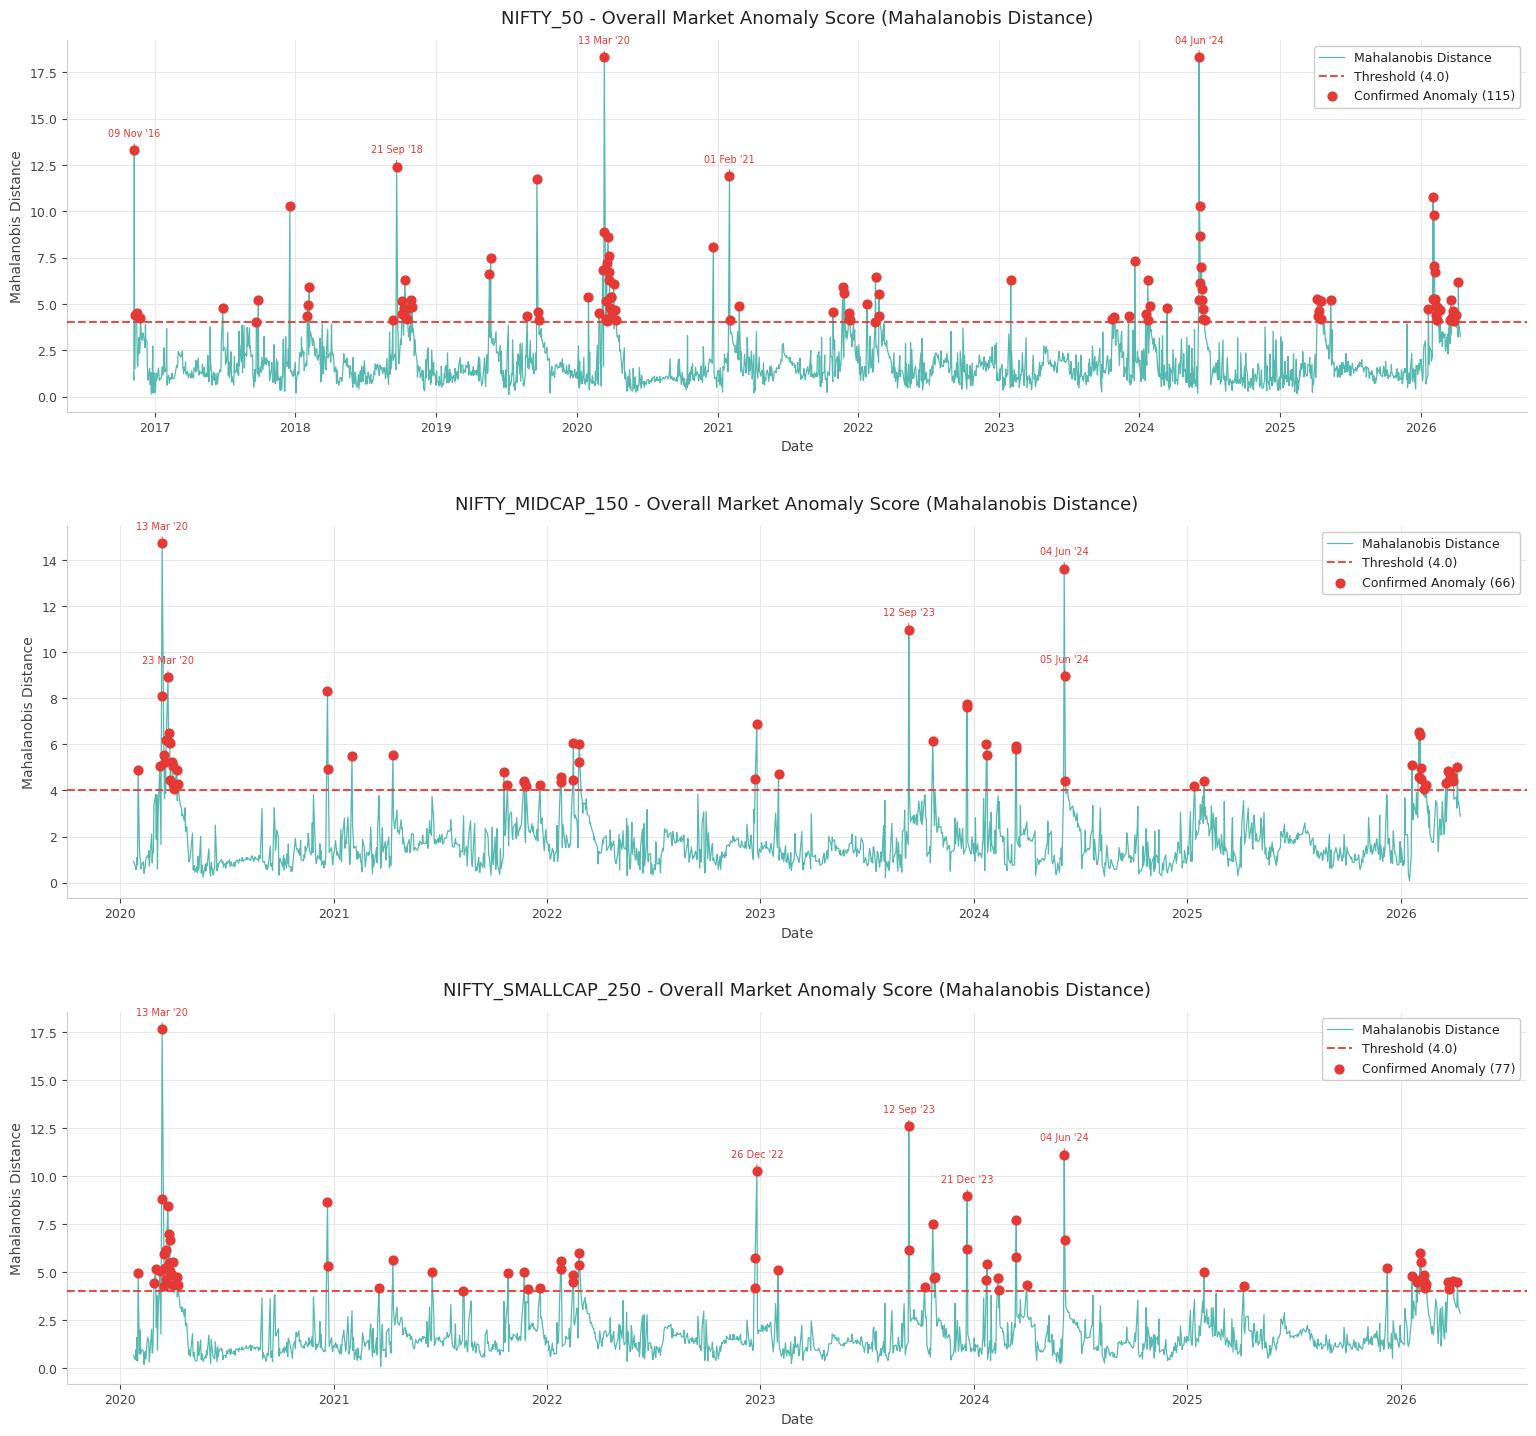

In [5]:
csv_files = {
    "NIFTY_50":           "D:\\FIMIS\\FIMIS_Paper\\Z Only\\Market_Anomaly_Data_Updated\\NIFTY_50_ANALYZED_ZSCORES.csv",
    "NIFTY_MIDCAP_150":   "D:\\FIMIS\\FIMIS_Paper\\Z Only\\Market_Anomaly_Data_Updated\\NIFTY_MIDCAP_150_ANALYZED_ZSCORES.csv",
    "NIFTY_SMALLCAP_250": "D:\\FIMIS\\FIMIS_Paper\\Z Only\\Market_Anomaly_Data_Updated\\NIFTY_SMALLCAP_250_ANALYZED_ZSCORES.csv",
}
 
FEATURES       = ["Daily_Return", "Price_Spread", "Volatility_21D"]
ROLLING_WINDOW = 126          # 1 trading year
CONFIDENCE     = 0.999        # chi-squared threshold
DOF            = len(FEATURES)
 
THRESHOLD = np.sqrt(chi2.ppf(CONFIDENCE, df=DOF))
print(f"Anomaly threshold (Mahalanobis distance): {THRESHOLD:.4f}\n")
 
# ── Palette ───────────────────────────────────────────────────────────────────
LINE_COLOR    = "#4DB6AC"    # teal
ANOMALY_COLOR = "#E53935"    # red
 
 
# ── Helpers ───────────────────────────────────────────────────────────────────
def compute_rolling_mahalanobis(df, features, window):
    X = df[features].values
    n = len(X)
    distances = np.full(n, np.nan)
 
    for i in range(window, n):
        X_window = X[i - window: i]
        mean_w   = X_window.mean(axis=0)
        cov_w    = np.cov(X_window, rowvar=False)
        try:
            inv_cov = np.linalg.inv(cov_w)
        except np.linalg.LinAlgError:
            continue
        distances[i] = mahalanobis(X[i], mean_w, inv_cov)
 
    return pd.Series(distances, index=df.index, name="Mahal_Distance")
 
 
def load_and_compute(path, label):
    df = pd.read_csv(path, parse_dates=["Date"])
    df.sort_values("Date", inplace=True)
    df.reset_index(drop=True, inplace=True)
 
    df.dropna(subset=FEATURES, inplace=True)
    df.reset_index(drop=True, inplace=True)
 
    df["Mahal_Distance"] = compute_rolling_mahalanobis(df, FEATURES, ROLLING_WINDOW)
    df["Is_Anomaly"]     = df["Mahal_Distance"] > THRESHOLD
 
    n_anomalies = df["Is_Anomaly"].sum()
    print(f"{label}: {len(df)} rows  |  {n_anomalies} anomalies detected")
    return df
 
 
# ── Load ──────────────────────────────────────────────────────────────────────
results = {}
for label, path in csv_files.items():
    try:
        results[label] = load_and_compute(path, label)
    except FileNotFoundError as e:
        print(f"[WARNING] File not found: {path} — skipping {label}. Error: {e}")
 
if not results:
    raise RuntimeError("No data loaded. Check that CSV files are in the working directory.")
 
 
# ── Plot ──────────────────────────────────────────────────────────────────────
plt.style.use("default")
 
fig, axes = plt.subplots(
    nrows=len(results), ncols=1,
    figsize=(16, 5 * len(results)),
    facecolor="white"
)
if len(results) == 1:
    axes = [axes]
 
for ax, (label, df) in zip(axes, results.items()):
 
    ax.set_facecolor("white")
    ax.tick_params(colors="#444444", labelsize=9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#CCCCCC")
    ax.spines["bottom"].set_color("#CCCCCC")
    ax.grid(True, color="#E8E8E8", linewidth=0.7)
 
    valid = df.dropna(subset=["Mahal_Distance"])
 
    # ── main distance line
    ax.plot(valid["Date"], valid["Mahal_Distance"],
            color=LINE_COLOR, linewidth=0.9, alpha=0.95,
            label="Mahalanobis Distance", zorder=2)
 
    # ── threshold dashed line
    ax.axhline(THRESHOLD, color=ANOMALY_COLOR, linewidth=1.5,
               linestyle="--", alpha=0.9,
               label=f"Threshold ({THRESHOLD:.1f})", zorder=3)
 
    # ── anomaly scatter dots
    anomalies = valid[valid["Is_Anomaly"]]
    ax.scatter(anomalies["Date"], anomalies["Mahal_Distance"],
               color=ANOMALY_COLOR, s=40, zorder=4,
               label=f"Confirmed Anomaly ({len(anomalies)})")
 
    # ── title matching reference style
    ax.set_title(
        f"{label} - Overall Market Anomaly Score (Mahalanobis Distance)",
        fontsize=13, fontweight="normal", color="#212121",
        pad=12, loc="center"
    )
 
    ax.set_ylabel("Mahalanobis Distance", color="#444444", fontsize=10)
    ax.set_xlabel("Date", color="#444444", fontsize=10)
 
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_major_locator(mdates.YearLocator())
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=0, ha="center")
 
    ax.legend(
        facecolor="white", edgecolor="#CCCCCC",
        labelcolor="#212121", fontsize=9,
        loc="upper right", framealpha=1.0
    )
 
    # ── annotate top 5 extreme anomalies with date labels
    top5 = anomalies.nlargest(5, "Mahal_Distance")
    for _, row in top5.iterrows():
        ax.annotate(
            row["Date"].strftime("%d %b '%y"),
            xy=(row["Date"], row["Mahal_Distance"]),
            xytext=(0, 10), textcoords="offset points",
            fontsize=7, color=ANOMALY_COLOR, ha="center",
            arrowprops=dict(arrowstyle="-", color=ANOMALY_COLOR, lw=0.6)
        )
 
plt.tight_layout(pad=3.0)
output_path = "D:\\FIMIS\\FIMIS_Paper\\Z Only\\Market_Anomaly_Data_Updated\\nifty_anomaly_detection.png"
plt.savefig(output_path, dpi=150, bbox_inches="tight", facecolor="white")
print(f"\nPlot saved → {output_path}")
plt.show()


PHASE 4: CROSS-MARKET DIVERGENCE ANOMALIES

 -> Saved Divergence Data to: Market_Anomaly_Data_Updated\Market_Divergences_ZSCORES.csv



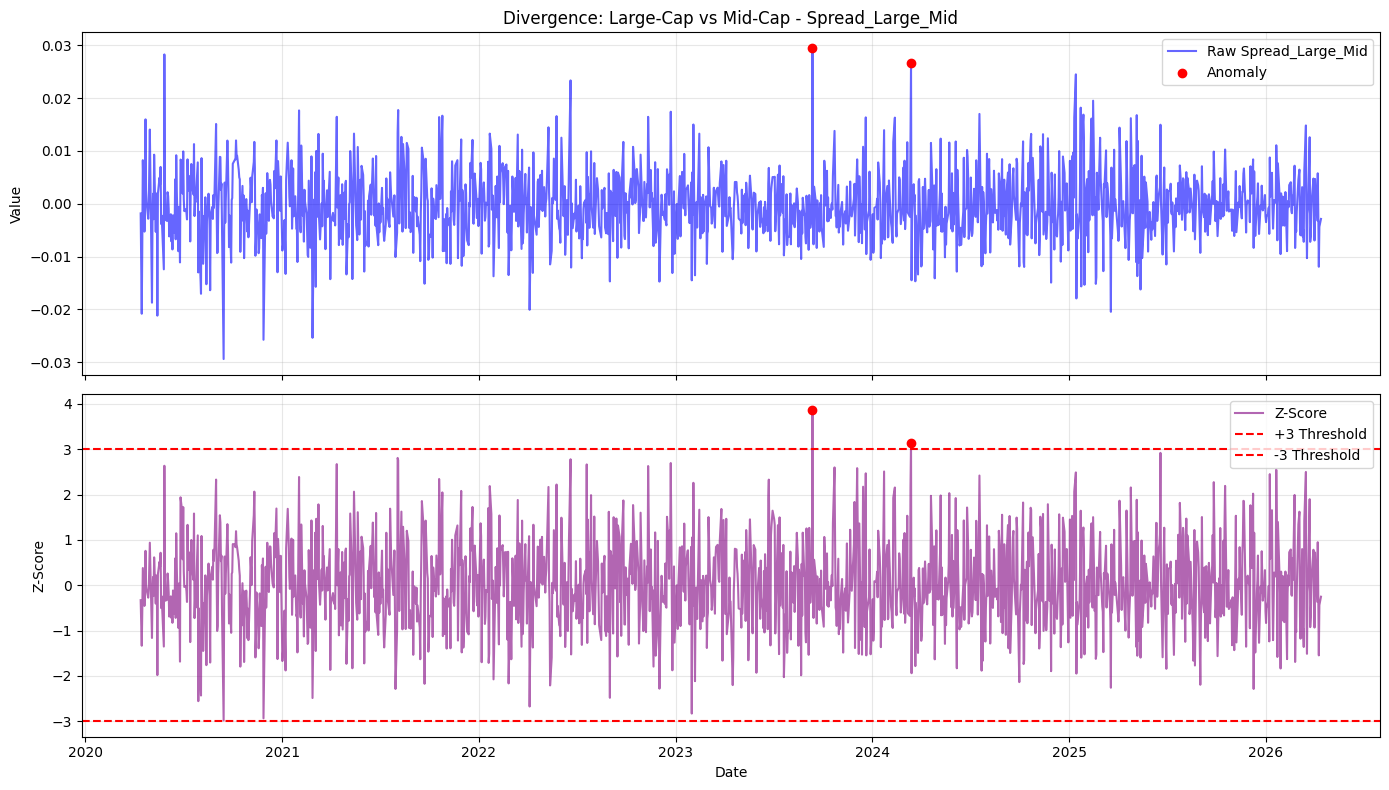

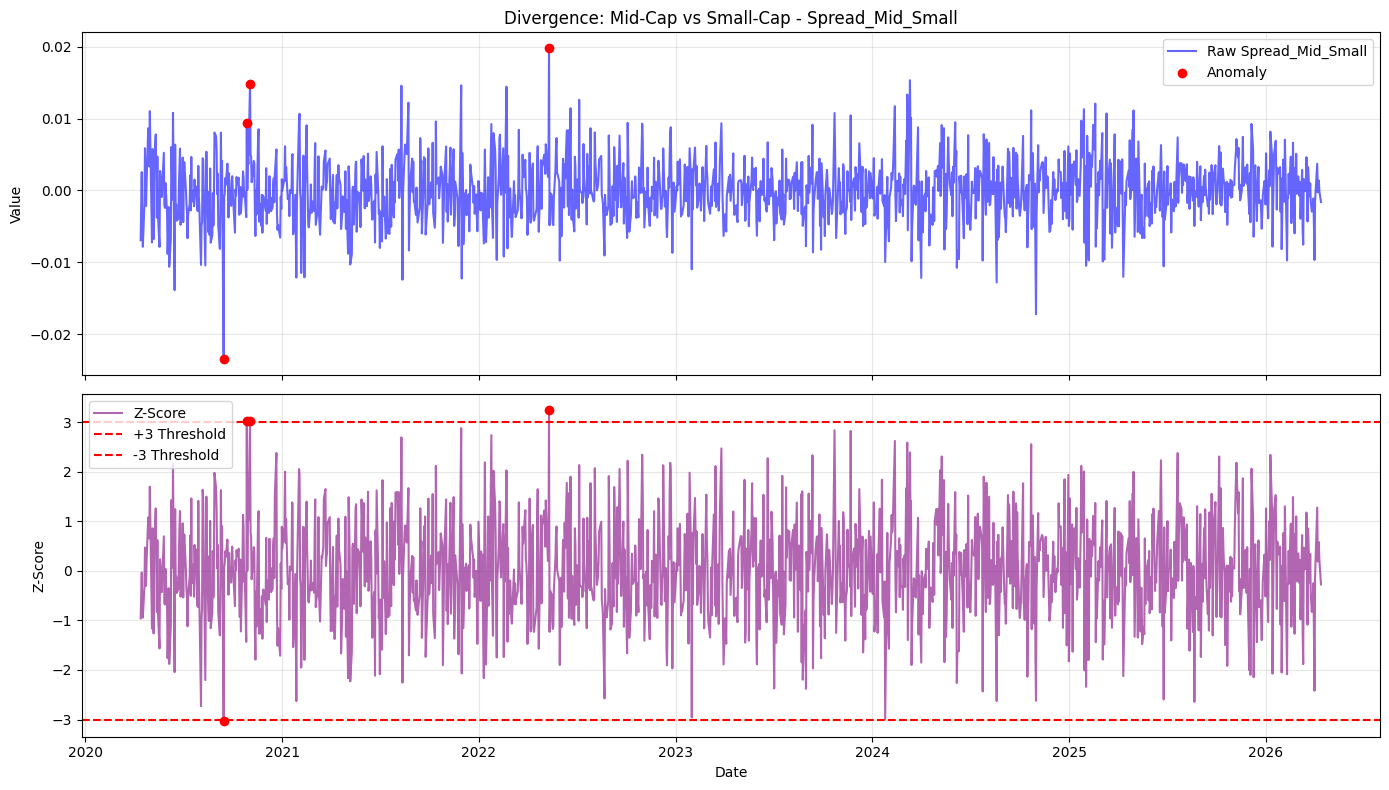

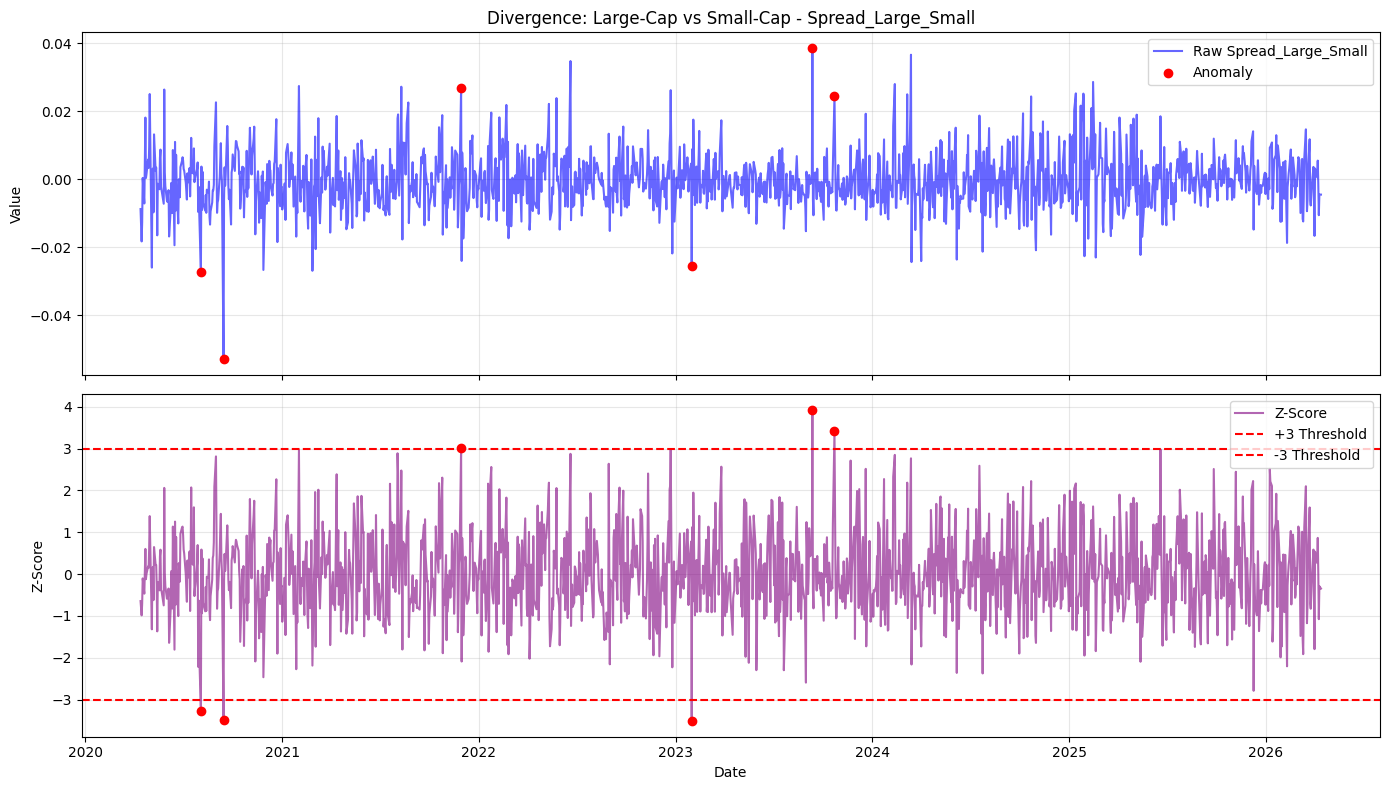

In [6]:
print("\n==========================================")
print("PHASE 4: CROSS-MARKET DIVERGENCE ANOMALIES")
print("==========================================\n")

# 1. Extract and align the 'Close' prices from the three separate CSVs
# We merge them into one DataFrame first to ensure dates perfectly match up
aligned_data = {}
for name, filename in csv_files.items():
    if os.path.exists(filename):
        df = pd.read_csv(filename, index_col='Date', parse_dates=True)
        aligned_data[name] = df['Close']
    else:
        print(f"ERROR: {filename} not found.")

div_df = pd.DataFrame(aligned_data).dropna()

# Calculate Daily Returns for each index (Step 1 from the mathematical formula)
div_df['Ret_Large'] = div_df['NIFTY_50'].pct_change()
div_df['Ret_Mid'] = div_df['NIFTY_MIDCAP_150'].pct_change()
div_df['Ret_Small'] = div_df['NIFTY_SMALLCAP_250'].pct_change()

# 2. Calculate the Spreads (Step 2: Core Idea)
div_df['Spread_Large_Mid'] = div_df['Ret_Large'] - div_df['Ret_Mid']
div_df['Spread_Mid_Small'] = div_df['Ret_Mid'] - div_df['Ret_Small']
div_df['Spread_Large_Small'] = div_df['Ret_Large'] - div_df['Ret_Small']

# 3. Normalize into Z-Scores using a 21-day rolling window (Step 3: Normalization)
for pair in ['Large_Mid', 'Mid_Small', 'Large_Small']:
    spread_col = f'Spread_{pair}'
    z_col = f'Z_Divergence_{pair}'
    
    roll_mean = div_df[spread_col].rolling(window=21).mean()
    roll_std = div_df[spread_col].rolling(window=21).std()
    
    div_df[z_col] = (div_df[spread_col] - roll_mean) / roll_std

# Drop the NaN values created by pct_change and the 21-day rolling windows
div_df.dropna(inplace=True)

# 4. Save to a new CSV in the output directory
output_dir = "Market_Anomaly_Data_Updated"
div_filename = os.path.join(output_dir, "Market_Divergences_ZSCORES.csv")
div_df.to_csv(div_filename)
print(f" -> Saved Divergence Data to: {div_filename}\n")

# 5. Visualizations (Step 4 & Final Interpretation)
# Filter for the last 6 years to match your previous charts
cutoff_date_div = div_df.index.max() - pd.DateOffset(years=6)
div_recent = div_df[div_df.index >= cutoff_date_div]

# Plot the three divergence pairs using the function from the previous cell
plot_anomalies(div_recent, 'Spread_Large_Mid', 'Z_Divergence_Large_Mid', "Divergence: Large-Cap vs Mid-Cap")
plot_anomalies(div_recent, 'Spread_Mid_Small', 'Z_Divergence_Mid_Small', "Divergence: Mid-Cap vs Small-Cap")
plot_anomalies(div_recent, 'Spread_Large_Small', 'Z_Divergence_Large_Small', "Divergence: Large-Cap vs Small-Cap")


PHASE 5: LEAD-LAG BUBBLE DETECTION

Calculating Rolling Lead-Lag over a 21-day window...
 -> Saved Lead-Lag Data to: Market_Anomaly_Data_Updated\Lead_Lag_Bubble_Signals.csv



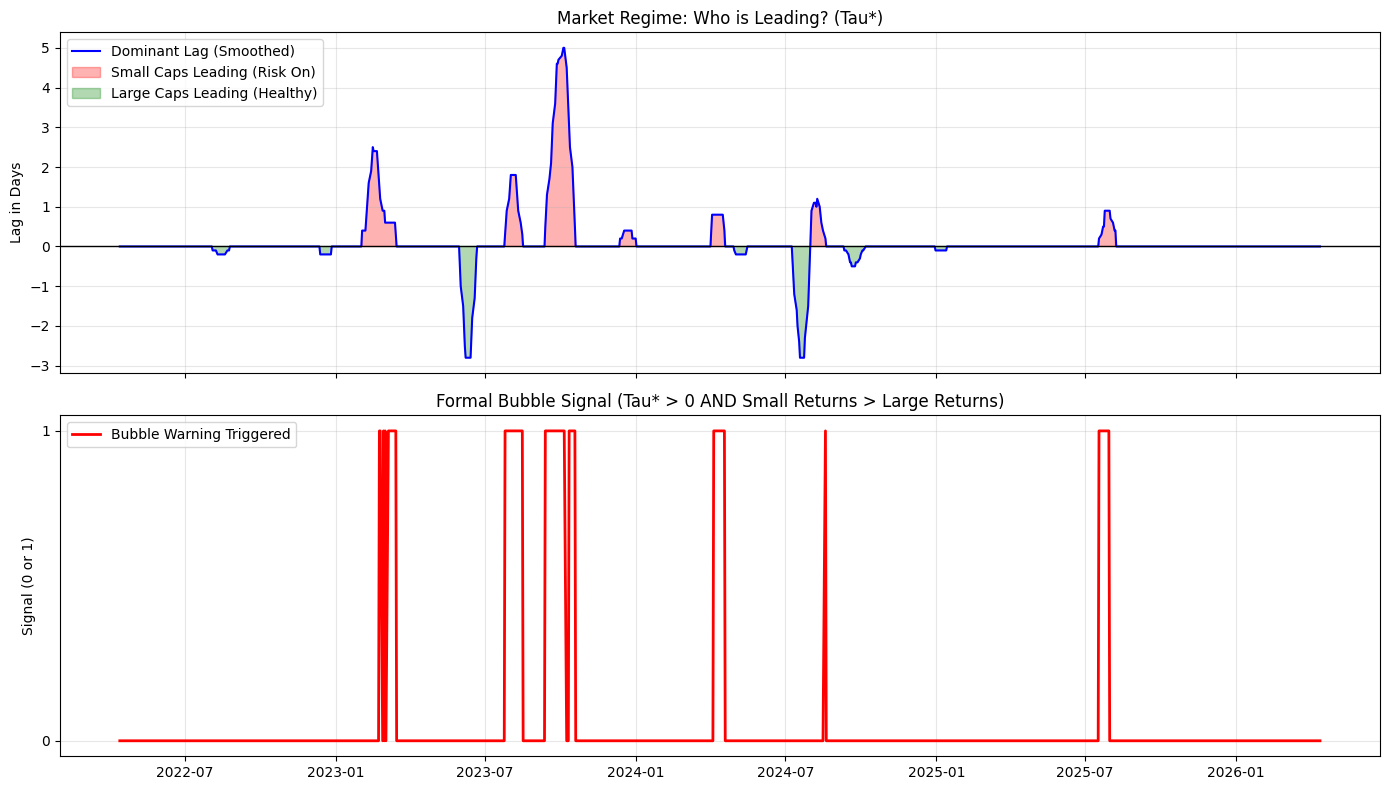

In [7]:
print("\n==========================================")
print("PHASE 5: LEAD-LAG BUBBLE DETECTION")
print("==========================================\n")

# --- 1. Load and Align Data ---
# We only need NIFTY 50 (Large) and SMALLCAP 250 (Small) for this
csv_large = csv_files.get("NIFTY_50")
csv_small = csv_files.get("NIFTY_SMALLCAP_250")

if not (os.path.exists(csv_large) and os.path.exists(csv_small)):
    print("ERROR: Missing required CSV files for Large or Small caps.")
else:
    df_L = pd.read_csv(csv_large, index_col='Date', parse_dates=True)
    df_S = pd.read_csv(csv_small, index_col='Date', parse_dates=True)
    
    # Align dates and calculate raw daily returns
    ll_df = pd.DataFrame({
        'Ret_Large': df_L['Close'].pct_change(),
        'Ret_Small': df_S['Close'].pct_change()
    }).dropna()
    
    # --- 2. Configuration for Rolling Cross-Correlation ---
    window_size = 21  # 21-day rolling window
    max_lag = 5       # Test shifts from -5 to +5 days
    
    tau_stars = []
    
    # --- 3. Compute Dominant Lag (tau*) over Time ---
    print(f"Calculating Rolling Lead-Lag over a {window_size}-day window...")
    
    for i in range(len(ll_df)):
        # Ensure we have enough historical data for the window
        if i < window_size:
            tau_stars.append(np.nan)
            continue
            
        # Extract the 30-day historical window for both indices
        window_L = ll_df['Ret_Large'].iloc[i - window_size : i]
        window_S = ll_df['Ret_Small'].iloc[i - window_size : i]
        
        correlations = []
        lags = range(-max_lag, max_lag + 1)
        
        # Test every lag from -5 to +5
        for lag in lags:
            # Shift Large-Caps by 'lag'. 
            # If lag > 0 (Small leads), we align today's Small with tomorrow's Large.
            shifted_L = window_L.shift(-lag)
            
            # Calculate correlation (dropping NaNs caused by the shift)
            corr = window_S.corr(shifted_L)
            correlations.append(corr if not np.isnan(corr) else 0)
            
        # Find the lag that produced the absolute highest correlation
        best_lag_idx = np.argmax(correlations)
        tau_stars.append(lags[best_lag_idx])
        
    ll_df['Tau_Star'] = tau_stars
    
    # Smooth the signal to avoid daily noise (Consistency check)
    ll_df['Tau_Star_Smoothed'] = ll_df['Tau_Star'].rolling(window=10).mean()
    
    # --- 4. The Bubble Condition ---
    # Condition 1: Small Caps are consistently leading (Tau* > 0)
    cond_lead = ll_df['Tau_Star_Smoothed'] > 0
    
    # Condition 2: Small Caps have higher returns over the window
    ll_df['Cum_Ret_Large'] = (1 + ll_df['Ret_Large']).rolling(window_size).apply(np.prod) - 1
    ll_df['Cum_Ret_Small'] = (1 + ll_df['Ret_Small']).rolling(window_size).apply(np.prod) - 1
    cond_return = ll_df['Cum_Ret_Small'] > ll_df['Cum_Ret_Large']
    
    # Final Formal Bubble Signal (1 if both true, 0 otherwise)
    ll_df['Bubble_Signal'] = np.where(cond_lead & cond_return, 1, 0)
    
    # Save the output
    output_dir = "Market_Anomaly_Data_Updated"
    ll_filename = os.path.join(output_dir, "Lead_Lag_Bubble_Signals.csv")
    ll_df.to_csv(ll_filename)
    print(f" -> Saved Lead-Lag Data to: {ll_filename}\n")
    
    # --- 5. Visualization ---
    # Plot the last 4 years to see the regimes clearly
    cutoff = ll_df.index.max() - pd.DateOffset(years=4)
    plot_df = ll_df[ll_df.index >= cutoff]
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    
    # Top Plot: Smoothed Dominant Lag (Tau*)
    ax1.plot(plot_df.index, plot_df['Tau_Star_Smoothed'], color='blue', label='Dominant Lag (Smoothed)')
    ax1.axhline(0, color='black', linestyle='-', linewidth=1)
    ax1.fill_between(plot_df.index, 0, plot_df['Tau_Star_Smoothed'], where=(plot_df['Tau_Star_Smoothed'] > 0), color='red', alpha=0.3, label='Small Caps Leading (Risk On)')
    ax1.fill_between(plot_df.index, 0, plot_df['Tau_Star_Smoothed'], where=(plot_df['Tau_Star_Smoothed'] <= 0), color='green', alpha=0.3, label='Large Caps Leading (Healthy)')
    ax1.set_title("Market Regime: Who is Leading? (Tau*)")
    ax1.set_ylabel("Lag in Days")
    ax1.legend(loc='upper left')
    ax1.grid(True, alpha=0.3)
    
    # Bottom Plot: The Binary Bubble Signal
    ax2.plot(plot_df.index, plot_df['Bubble_Signal'], color='red', linewidth=2, label='Bubble Warning Triggered')
    ax2.set_title("Formal Bubble Signal (Tau* > 0 AND Small Returns > Large Returns)")
    ax2.set_ylabel("Signal (0 or 1)")
    ax2.set_yticks([0, 1])
    ax2.legend(loc='upper left')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()